In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(r"pakistan_tech_jobs_final.csv")

In [4]:
df.drop('job_description',inplace=True,axis=1)

In [5]:
df.isna().sum()
df['education']=df['education'].fillna(df['education'].mode()[0])

In [6]:
#K means to cluster job categories
#Linear to predict min max salries 
#logistic to predict job_title
#KNN to predict five related jobs
#firstly preprocessing
df['job_title']=df['job_title'].fillna(df['job_title'].mode()[0])
df.isna().sum()
df.duplicated().sum()#No Duplicates

np.int64(0)

In [7]:
clustering_df=df.copy()
clustering_df.head()

,job_id,job_title,company,required_skills,city,province,experience_min,experience_max,education,employment_type,work_mode,salary_min,salary_max,posted_date,job_category,source_website
0,1001,Senior Full-Stack & AI Engineer,Jack Mitchel,"Python, JavaScript, TypeScript, Node.js, React...",Karachi,Sindh,5.0,8.0,Bachelor's,Full-time,Remote,560000.0,840000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
1,1002,"Front end developer, UI/UX Designing",Sharp Mind,"HTML, CSS, Java, UI/UX Design",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,80000.0,110000.0,2026-10-30,Web Development,Bano Qabil Jobs
2,1003,MACHINE LEARNING ENGINNER,MUHAMMAD AFNAN,"Core ML Expertise, Solid Programming (Python, ...",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,60000.0,100000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs
3,1004,Frontend Developer (React + Next.js),VertexInvo,"React, Next.js",Karachi,Sindh,2.0,5.0,Bachelor's,Full-time,On-site,50000.0,60000.0,2026-10-30,Web Development,Bano Qabil Jobs
4,1005,Mobile App Developer (Flutter),Mohsin Shiekh,"Python, JavaScript, SQL, Git",Karachi,Sindh,0.0,2.0,Bachelor's,Full-time,Remote,40000.0,59998.0,2026-10-30,Mobile Development,Bano Qabil Jobs


In [7]:
senior_kw = ['senior', 'sr', 'lead', 'principal', 'architect', 'head', 'manager', 'director']
clustering_df['is_senior'] = df['job_title'].fillna('').str.lower().apply(lambda t: int(any(k in t for k in senior_kw)))
clustering_df.head()

,job_id,job_title,company,required_skills,city,province,experience_min,experience_max,education,employment_type,work_mode,salary_min,salary_max,posted_date,job_category,source_website,is_senior
0,1001,Senior Full-Stack & AI Engineer,Jack Mitchel,"Python, JavaScript, TypeScript, Node.js, React...",Karachi,Sindh,5.0,8.0,Bachelor's,Full-time,Remote,560000.0,840000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs,1
1,1002,"Front end developer, UI/UX Designing",Sharp Mind,"HTML, CSS, Java, UI/UX Design",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,80000.0,110000.0,2026-10-30,Web Development,Bano Qabil Jobs,0
2,1003,MACHINE LEARNING ENGINNER,MUHAMMAD AFNAN,"Core ML Expertise, Solid Programming (Python, ...",Lahore,Punjab,2.0,5.0,Bachelor's,Full-time,On-site,60000.0,100000.0,2026-10-30,Data Science / AI / ML,Bano Qabil Jobs,0
3,1004,Frontend Developer (React + Next.js),VertexInvo,"React, Next.js",Karachi,Sindh,2.0,5.0,Bachelor's,Full-time,On-site,50000.0,60000.0,2026-10-30,Web Development,Bano Qabil Jobs,0
4,1005,Mobile App Developer (Flutter),Mohsin Shiekh,"Python, JavaScript, SQL, Git",Karachi,Sindh,0.0,2.0,Bachelor's,Full-time,Remote,40000.0,59998.0,2026-10-30,Mobile Development,Bano Qabil Jobs,0


In [8]:
cols_to_drop=['job_id','job_title','company','required_skills','city','province','employment_type','work_mode','posted_date','job_category','source_website']
clustering_df.drop(columns=cols_to_drop,inplace=True)


In [9]:
clustering_df.head()

,experience_min,experience_max,education,salary_min,salary_max,is_senior
0,5.0,8.0,Bachelor's,560000.0,840000.0,1
1,2.0,5.0,Bachelor's,80000.0,110000.0,0
2,2.0,5.0,Bachelor's,60000.0,100000.0,0
3,2.0,5.0,Bachelor's,50000.0,60000.0,0
4,0.0,2.0,Bachelor's,40000.0,59998.0,0


In [10]:
clustering_df['avg_experience']=(clustering_df['experience_min']+clustering_df['experience_max'])/2
clustering_df['avg_sal']=(clustering_df['salary_min']+clustering_df['salary_max'])/2

In [11]:
clustering_df.drop(columns=['experience_min','experience_max','salary_min','salary_max'],inplace=True)

In [12]:
clustering_df.head()

,education,is_senior,avg_experience,avg_sal
0,Bachelor's,1,6.5,700000.0
1,Bachelor's,0,3.5,95000.0
2,Bachelor's,0,3.5,80000.0
3,Bachelor's,0,3.5,55000.0
4,Bachelor's,0,1.0,49999.0


In [13]:
clustering_df['education']=clustering_df['education'].replace({"Bachelor's":0,"Master's":1})

In [14]:
from sklearn.preprocessing import StandardScaler
clustering_scaler=StandardScaler()

In [15]:
scaling_cols=['avg_experience','avg_sal']

In [16]:
clustering_df[scaling_cols]=clustering_scaler.fit_transform(clustering_df[scaling_cols])

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

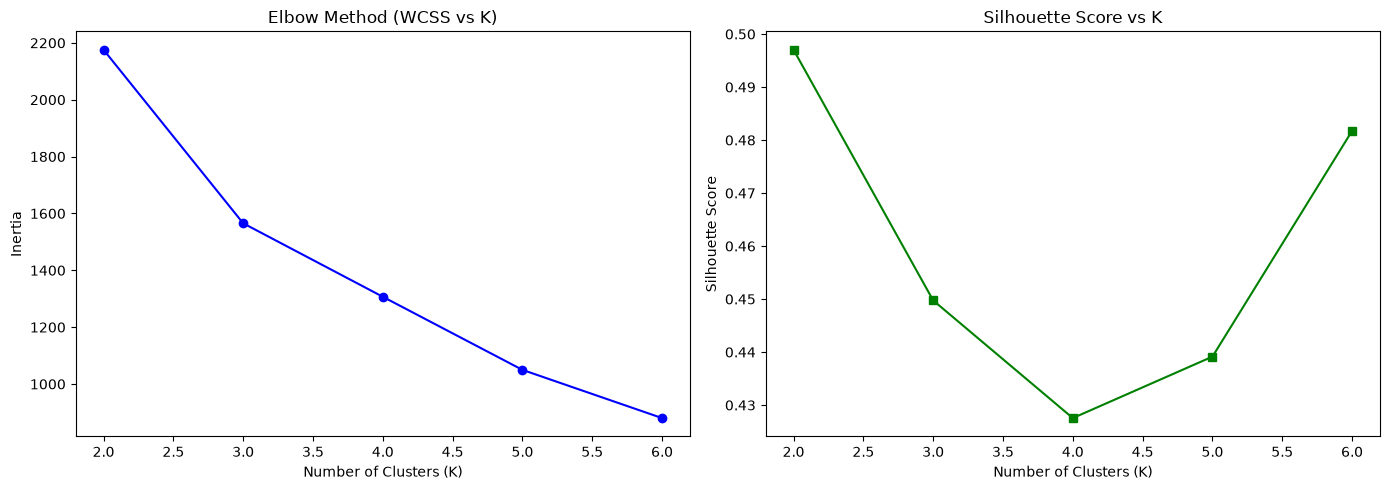

In [18]:
inertia = []
silhouette_scores = []
k_range = range(2, 7)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(clustering_df)
    inertia.append(km.inertia_)
    silhouette_scores.append(silhouette_score(clustering_df, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(k_range, inertia, marker='o', color='b')
ax[0].set_title('Elbow Method (WCSS vs K)')
ax[0].set_xlabel('Number of Clusters (K)')
ax[0].set_ylabel('Inertia')
ax[1].plot(k_range, silhouette_scores, marker='s', color='g')
ax[1].set_title('Silhouette Score vs K')
ax[1].set_xlabel('Number of Clusters (K)')
ax[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

In [19]:
optimal_k = 3
km_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clustering_df['Cluster'] = km_final.fit_predict(clustering_df)
print(f"Converged in: {km_final.n_iter_} iterations")
print(f"Final Silhouette Score: {silhouette_score(clustering_df.drop(columns=['Cluster']), clustering_df['Cluster']):.4f}")
cluster_summary = clustering_df.groupby('Cluster').mean()
cluster_summary

Converged in: 4 iterations
Final Silhouette Score: 0.4497


,education,is_senior,avg_experience,avg_sal
Cluster,,,,
0,0.351159,0.068627,-0.806934,-0.725292
1,0.371968,0.172507,1.601236,1.534182
2,0.318462,0.098462,0.478956,0.376301


In [20]:
clustering_df.groupby('Cluster')[['avg_experience', 'avg_sal', 'is_senior']].mean()

,avg_experience,avg_sal,is_senior
Cluster,,,
0,-0.806934,-0.725292,0.068627
1,1.601236,1.534182,0.172507
2,0.478956,0.376301,0.098462


In [ ]:
#Cluster 0 represents junior 1 lead and 2 represents mid